# Contração e diversidade de parâmetros: 100 mil ASTs

## Exemplo inicial: $3x+c$ e $2x+c$ viram a mesma série?

**Não em geral.** O multiplicador atua sobre a expressão inteira, inclusive o intercepto.
Com Shao–Wu, quando o limite está ativo, $ax+b$ (a positivo) vira
$0{,}76x+0{,}76b/a$. Assim, $3x+1$ e $2x+1$ têm o mesmo coeficiente de x,
mas interceptos diferentes. Já $3x+1{,}5$ e $2x+1$ são proporcionais e podem colidir.
No Jacobiano também intervém o limite de invariância do domínio.

O relatório, em `report/english/chapters/implemented_generator/06_generation_overview.tex`,
linhas 116–135 (R1/R2), compara **x e 2x, sem intercepto**: ambos viram
0,855x no Jacobiano e 0,76x no Shao–Wu. O exemplo está correto.
O script `scripts/check_generation_overview.py` é executado abaixo para conferir os nove exemplos.
Equações iguais só produzem trajetórias iguais quando histórico e inovações numéricas também são iguais.
Não confundimos colisão de mecanismos com convergência temporal de trajetórias.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform, subprocess, time
from dataclasses import asdict, replace
from collections import defaultdict
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from tsfmxai.generators.random_expression import RandomTreeConfig, sample_random_mechanism, derive_sample_seed
from tsfmxai.generators.contraction import ContractionTreeConfig, build_contractive_mechanism
from tsfmxai.generators.shao_wu import ShaoWuConfig, build_shao_wu_mechanism, saturate_product_lags
from tsfmxai.generators.stochastic import simulate_innovation_path
from tsfmxai.representations.expression import Add, Multiply, Parameter, Lag, MechanismBinding, to_bound_formula
from tsfmxai.representations.canonical_polynomial import canonicalize_polynomial

ROOT_SEED = 20261117
PATH_SEED = 71823
N_UNIVARIATE = 60_000
N_BIVARIATE_SYSTEMS = 20_000  # duas ASTs por sistema: total = 100 mil
TREE = RandomTreeConfig(minimum_operators=1, maximum_operators=3, num_series=1,
    minimum_lag=1, maximum_lag=3, parameter_probability=.55, lag_probability=.45,
    add_probability=.8, minimum_parameter_magnitude=.05, maximum_parameter_magnitude=3.,
    require_lag=True, coefficient_gate_lags=True)
J_CONFIG = ContractionTreeConfig(tree_config=TREE, innovation_bound=float(np.sqrt(3)*.05))
F_CONFIG = ShaoWuConfig(tree_config=TREE)
F2_CONFIG = replace(F_CONFIG, tree_config=replace(TREE, num_series=2))
DECIMALS = (6, 9, 12)
MAX_DEGREE = 4  # no máximo quatro folhas originais; gates não aumentam o grau
started = time.perf_counter()
report_check = subprocess.run([sys.executable, str(ROOT/'scripts/check_generation_overview.py')],
    cwd=ROOT, capture_output=True, text=True, check=True)
print(report_check.stdout)


R1: seed=0; input=x_0(t-1); scales=0.855, 0.76
    Heaps: x_0(t) = (0 + (0.707107 * x_0(t-1))) + epsilon_0(t)
R2: seed=0; input=(x_0(t-1) * 2); scales=0.4275, 0.38
    Heaps: x_0(t) = (0 + (0.894427 * x_0(t-1))) + epsilon_0(t)
R3: seed=2; input=(x_0(t-1) + -0.5); scales=0.578485058, 0.76
    Heaps: x_0(t) = (-0.5 + (0.707107 * x_0(t-1))) + epsilon_0(t)
R4: seed=0; input=(x_0(t-1) + x_0(t-3)); scales=0.333658537, 0.38
    Heaps: x_0(t) = (((0 + (0.707107 * x_0(t-1))) + (-0.5 * x_0(t-2))) + (0.707107 * x_0(t-3))) + epsilon_0(t)
R5: seed=0; input=x_0(t-12); scales=0.0734439408, 0.76
    Heaps: x_0(t) = (0 + (0.707107 * x_0(t-12))) + epsilon_0(t)
R6: seed=0; input=(x_0(t-1) * x_0(t-2)); scales=0.38, 0.38
R7: seed=0; input=(x_0(t-1) * x_0(t-1)); scales=0.4275, 0.38
R8: seed=5; input=(x_0(t-1) * (x_0(t-2) * (x_0(t-3) * x_0(t-1)))); scales=0.177662338, 0.19
R9: seed=1438; input=((x_0(t-1) * x_0(t-2)) + (0.5 * x_0(t-1))); scales=0.310909091, 0.304
Verified nine sampled ASTs, 18 transformations

,input,method,scale,intercept,slope
0,x,Jacobian,0.855000,0.000000,0.855000
1,x,Shao-Wu,0.760000,0.000000,0.760000
2,2x,Jacobian,0.427500,0.000000,0.855000
3,2x,Shao-Wu,0.380000,0.000000,0.760000
4,3x+1,Jacobian,0.216932,0.216932,0.650796
5,3x+1,Shao-Wu,0.253333,0.253333,0.760000
6,2x+1,Jacobian,0.289243,0.289243,0.578485
7,2x+1,Shao-Wu,0.380000,0.380000,0.760000
8,3x+1.5,Jacobian,0.192828,0.289243,0.578485
9,3x+1.5,Shao-Wu,0.253333,0.380000,0.760000


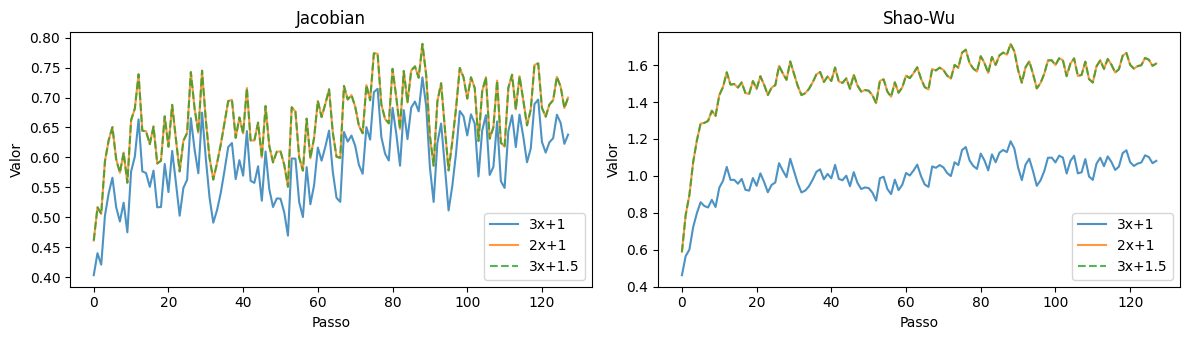

,method,pair,max_abs_difference
0,Jacobian,x vs 2x,0.000000e+00
1,Jacobian,3x+1 vs 2x+1,9.093843e-02
2,Jacobian,3x+1.5 vs 2x+1,2.220446e-16
3,Shao-Wu,x vs 2x,0.000000e+00
4,Shao-Wu,3x+1 vs 2x+1,5.277778e-01
5,Shao-Wu,3x+1.5 vs 2x+1,1.554312e-15


In [2]:
affine = Add(Multiply(Parameter('a'), Lag(0, 'L')), Parameter('b'))
examples, example_mechanisms = [], {}
for label, a, b in [('x',1.,0.), ('2x',2.,0.), ('3x+1',3.,1.), ('2x+1',2.,1.), ('3x+1.5',3.,1.5)]:
    binding = MechanismBinding({'a':a,'b':b}, {'L':1})
    j = build_contractive_mechanism(affine,binding,J_CONFIG)
    f = build_shao_wu_mechanism((affine,),(binding,),F_CONFIG)
    for method,e,v,s in [('Jacobian',j.expression,j.binding,j.scale),
                          ('Shao-Wu',f.expressions[0],f.bindings[0],f.scale)]:
        examples.append(dict(input=label,method=method,scale=s,intercept=s*b,slope=s*a))
        example_mechanisms[label,method] = (e,v)
display(pd.DataFrame(examples))
noise = np.random.default_rng(PATH_SEED).uniform(-np.sqrt(3)*.05,np.sqrt(3)*.05,(1,128))
initial = np.array([[.2]])
path_checks = []
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
for ax,method in zip(axes,['Jacobian','Shao-Wu']):
    paths = {}
    for label in ['x','2x','3x+1','2x+1','3x+1.5']:
        e,b = example_mechanisms[label,method]
        paths[label] = simulate_innovation_path((e,),(b,),initial,noise)[0]
    for left,right,expected in [('x','2x',True),('3x+1','2x+1',False),('3x+1.5','2x+1',True)]:
        difference = float(np.max(np.abs(paths[left]-paths[right])))
        assert (difference < 1e-12) == expected
        path_checks.append(dict(method=method,pair=f'{left} vs {right}',max_abs_difference=difference))
    for label in ['3x+1','2x+1','3x+1.5']:
        ax.plot(paths[label], label=label, alpha=.8, linestyle='--' if label=='3x+1.5' else '-')
    ax.set(title=method,xlabel='Passo',ylabel='Valor'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(path_checks))


## Desenho pareado e definição de skeleton

Geramos 60 mil ASTs univariadas e 20 mil sistemas de duas séries (40 mil ASTs), sem rejeição
por resultado. Cada AST usa somente lags 1–3 e 1–3 operadores antes dos gates de coeficiente.
Magnitudes dos parâmetros em [0,05; 3] tornam a região de contração ativa observável;
**este prior restrito não estima a frequência no prior padrão do benchmark**.

No conjunto univariado, cada AST passa pelo Jacobiano e pelo Shao–Wu. Nos sistemas bivariados,
somente Shao–Wu: o Jacobiano implementado não suporta múltiplas séries. O ganho Shao–Wu é
calculado conjuntamente; os parâmetros da outra equação também afetam a escala.

O skeleton é o suporte canônico ordenado: monômios com **série, lag resolvido, multiplicidade
e transformação RAW/TANH**, removendo apenas valores de coeficientes. Não agrupamos lags ou
séries distintos. A comparação condiciona no par (skeleton original, skeleton final), para
que todos os vetores comparados tenham coordenadas alinhadas. Mostramos também o estágio
de saturação sem escala, isolando mudanças RAW→TANH da contração de coeficientes.

Os parâmetros internos do AST não medem diretamente diversidade funcional: produtos e somas
podem esconder cancelamentos. Medimos os **coeficientes canônicos efetivos**, incluindo o
intercepto. Igualdade exata usa Fractions dos floats da implementação; grades decimais de
6, 9 e 12 casas capturam colisões numéricas, sem alegar equivalência simbólica. Compartilhar
uma célula da grade não é um teste geral de distância relativa. A redução de desvio padrão
sozinha não significa perda de informação; contamos também vetores distintos e colisões novas.


In [3]:
# Orquestração específica deste experimento; todos os construtores/canonicalização vêm de src/.
records = []
scales = []
ast_count = 0
certificate_count = 0
for cohort, system_count, n in [('univariate',N_UNIVARIATE,1),('bivariate',N_BIVARIATE_SYSTEMS,2)]:
    tree_config = TREE if n == 1 else F2_CONFIG.tree_config
    for system_id in range(system_count):
        sampled = []
        for target in range(n):
            seed = derive_sample_seed(ROOT_SEED,ast_count)
            sampled.append(sample_random_mechanism(tree_config,seed=seed,sample_index=ast_count))
            ast_count += 1
        saturated = tuple(saturate_product_lags(m.expression) for m in sampled)
        f = build_shao_wu_mechanism(saturated,tuple(m.binding for m in sampled),
                                  F_CONFIG if n==1 else F2_CONFIG)
        assert f.certificate.holds
        certificate_count += 1
        scales.append((cohort,'Shao-Wu',system_id,f.scale))
        j = None
        if n == 1:
            j = build_contractive_mechanism(sampled[0].expression,sampled[0].binding,J_CONFIG)
            assert j.certificate.holds
            certificate_count += 1
            scales.append((cohort,'Jacobian',system_id,j.scale))
        for target,m in enumerate(sampled):
            original = canonicalize_polynomial(m.expression,m.binding,max_degree=MAX_DEGREE)
            variants = [('Original',m.expression,m.binding),('Saturation only',saturated[target],m.binding),
                        ('Shao-Wu',f.expressions[target],f.bindings[target])]
            if j is not None: variants.append(('Jacobian',j.expression,j.binding))
            for method,e,b in variants:
                p = original if method=='Original' else canonicalize_polynomial(e,b,max_degree=MAX_DEGREE)
                records.append((cohort,system_id,target,method,original.skeleton,p.skeleton,
                                original.coefficients,p.coefficients,
                                tuple(t.coefficient_exact for t in original.terms),
                                tuple(t.coefficient_exact for t in p.terms)))
        if (system_id+1)%10_000==0:
            print(cohort,system_id+1,'sistemas;',ast_count,'ASTs;',round(time.perf_counter()-started,1),'s')
assert ast_count == 100_000
df = pd.DataFrame(records,columns=['cohort','system','target','method','input_skeleton','skeleton',
                                  'input_coefficients','coefficients','input_exact','exact'])
del records
scale_df = pd.DataFrame(scales,columns=['cohort','method','system','scale'])
assert len(df)==360_000
print('ASTs:',ast_count,'| certificados válidos:',certificate_count,'| registros:',len(df))


univariate 10000 sistemas; 10000 ASTs; 14.8 s


univariate 20000 sistemas; 20000 ASTs; 27.5 s


univariate 30000 sistemas; 30000 ASTs; 39.2 s


univariate 40000 sistemas; 40000 ASTs; 51.0 s


univariate 50000 sistemas; 50000 ASTs; 63.8 s


univariate 60000 sistemas; 60000 ASTs; 76.1 s


bivariate 10000 sistemas; 80000 ASTs; 91.4 s


bivariate 20000 sistemas; 100000 ASTs; 106.9 s


ASTs: 100000 | certificados válidos: 140000 | registros: 360000


In [4]:
group_rows, slot_rows = [], []
for (cohort,method,source,support),g in df.groupby(['cohort','method','input_skeleton','skeleton'],sort=False):
    before = np.asarray(g.input_coefficients.tolist())
    after = np.asarray(g.coefficients.tolist())
    row = dict(cohort=cohort,method=method,input_skeleton=source,skeleton=support,n=len(g),
               unique_before_exact=len(set(g.input_exact)),unique_after_exact=len(set(g.exact)))
    for decimals in DECIMALS:
        a = [tuple(x) for x in np.round(before,decimals)]
        b = [tuple(x) for x in np.round(after,decimals)]
        outputs = defaultdict(set)
        for x,y in zip(a,b): outputs[y].add(x)
        merged = {key for key,values in outputs.items() if len(values)>1}
        row[f'unique_before_{decimals}'] = len(set(a))
        row[f'unique_after_{decimals}'] = len(outputs)
        row[f'new_collision_samples_{decimals}'] = sum(y in merged for y in b)
    group_rows.append(row)
    if len(g)>=20:
        for i,monomial in enumerate(support):
            values = after[:,i]
            slot_rows.append(dict(cohort=cohort,method=method,skeleton=support,monomial=monomial,n=len(g),
                minimum=values.min(),q05=np.quantile(values,.05),median=np.median(values),
                q95=np.quantile(values,.95),maximum=values.max(),std=values.std(),
                unique_9=len(set(np.round(values,9)))))
groups = pd.DataFrame(group_rows)
slots = pd.DataFrame(slot_rows)
summary_rows = []
for (cohort,method),g in groups.groupby(['cohort','method'],sort=False):
    row = dict(cohort=cohort,method=method,asts=int(g.n.sum()),skeleton_pairs=len(g),
               repeated_groups=int((g.n>1).sum()),samples_in_repeated_groups=int(g.loc[g.n>1,'n'].sum()),
               unique_before_exact=int(g.unique_before_exact.sum()),unique_after_exact=int(g.unique_after_exact.sum()))
    for d in DECIMALS:
        row[f'unique_before_{d}']=int(g[f'unique_before_{d}'].sum())
        row[f'unique_after_{d}']=int(g[f'unique_after_{d}'].sum())
        row[f'new_collision_sample_fraction_{d}']=float(g[f'new_collision_samples_{d}'].sum()/g.n.sum())
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
display(summary[['cohort','method','asts','skeleton_pairs','samples_in_repeated_groups',
                 'unique_before_9','unique_after_9','new_collision_sample_fraction_9']])
display(summary[['cohort','method','unique_before_exact','unique_after_exact',
                 *[f'new_collision_sample_fraction_{d}' for d in DECIMALS]]])
display(scale_df.groupby(['cohort','method']).scale.agg(['count','min','median','max']))
assert (summary.unique_before_exact >= summary.unique_before_12).all()
assert (summary.unique_after_exact >= summary.unique_after_12).all()
assert (summary.loc[summary.method=='Original','new_collision_sample_fraction_9']==0).all()


,cohort,method,asts,skeleton_pairs,samples_in_repeated_groups,unique_before_9,unique_after_9,new_collision_sample_fraction_9
0,univariate,Original,60000,229,59961,60000,60000,0.00000
1,univariate,Saturation only,60000,288,59951,60000,60000,0.00000
2,univariate,Shao-Wu,60000,288,59951,60000,54969,0.08445
3,univariate,Jacobian,60000,229,59961,60000,54480,0.09260
4,bivariate,Original,40000,975,39585,40000,40000,0.00000
5,bivariate,Saturation only,40000,1076,39526,40000,40000,0.00000
6,bivariate,Shao-Wu,40000,1076,39526,40000,39796,0.00590


,cohort,method,unique_before_exact,unique_after_exact,new_collision_sample_fraction_6,new_collision_sample_fraction_9,new_collision_sample_fraction_12
0,univariate,Original,60000,60000,0.000000,0.00000,0.00000
1,univariate,Saturation only,60000,60000,0.000000,0.00000,0.00000
2,univariate,Shao-Wu,60000,60000,0.084917,0.08445,0.08445
3,univariate,Jacobian,60000,60000,0.093667,0.09260,0.09260
4,bivariate,Original,40000,40000,0.000000,0.00000,0.00000
5,bivariate,Saturation only,40000,40000,0.000000,0.00000,0.00000
6,bivariate,Shao-Wu,40000,40000,0.005950,0.00590,0.00590


count       min    median   max
cohort     method                                   
bivariate  Shao-Wu   20000  0.009173  0.179982  0.95
univariate Jacobian  60000  0.006440  0.217110  0.95
           Shao-Wu   60000  0.007716  0.332239  0.95

### Variedade por skeleton (12 grupos mais frequentes de cada coorte/método)

,cohort,method,skeleton,n,unique_before_9,unique_after_9,new_collision_samples_9
21,univariate,Saturation only,"((), ((0, 2),))",11450,11450,11450,0
23,univariate,Jacobian,"((), ((0, 2),))",11450,11450,11450,0
22,univariate,Shao-Wu,"((), ((0, 2),))",11450,11450,11450,0
20,univariate,Original,"((), ((0, 2),))",11450,11450,11450,0
8,univariate,Original,"((), ((0, 1),))",11323,11323,11323,0
...,...,...,...,...,...,...,...
1190,bivariate,Original,"(((1, 3),),)",603,603,603,0
1191,bivariate,Saturation only,"(((1, 3),),)",603,603,603,0
1083,bivariate,Saturation only,"(((0, 1),),)",592,592,592,0
1082,bivariate,Original,"(((0, 1),),)",592,592,592,0


### Constantes efetivas: quantis e valores distintos por monômio

,cohort,method,skeleton,monomial,n,minimum,q05,median,q95,maximum,std,unique_9
42,univariate,Saturation only,"((), ((0, 2),))",(),11450,-20.443443,-3.659542,0.010929,3.820586,15.110876,2.439341,11450
47,univariate,Jacobian,"((), ((0, 2),))","((0, 2),)",11450,-0.684000,-0.684000,0.025065,0.684000,0.684000,0.444751,10050
46,univariate,Jacobian,"((), ((0, 2),))",(),11450,-0.860123,-0.715550,0.003756,0.719109,0.861369,0.477036,11450
45,univariate,Shao-Wu,"((), ((0, 2),))","((0, 2),)",11450,-0.760000,-0.760000,0.055575,0.760000,0.760000,0.683834,3224
44,univariate,Shao-Wu,"((), ((0, 2),))",(),11450,-13.081170,-2.239833,0.004173,2.331764,12.138484,1.432080,11450
43,univariate,Saturation only,"((), ((0, 2),))","((0, 2),)",11450,-18.042544,-2.933533,0.078770,2.885154,17.199068,2.166301,11450
41,univariate,Original,"((), ((0, 2),))","((0, 2),)",11450,-18.042544,-2.933533,0.078770,2.885154,17.199068,2.166301,11450
40,univariate,Original,"((), ((0, 2),))",(),11450,-20.443443,-3.659542,0.010929,3.820586,15.110876,2.439341,11450
25,univariate,Shao-Wu,"((), ((0, 1),))","((0, 1),)",11323,-0.760000,-0.760000,0.044389,0.760000,0.760000,0.682899,3203
26,univariate,Jacobian,"((), ((0, 1),))",(),11323,-0.856284,-0.716021,-0.010740,0.714648,0.860868,0.476367,11323


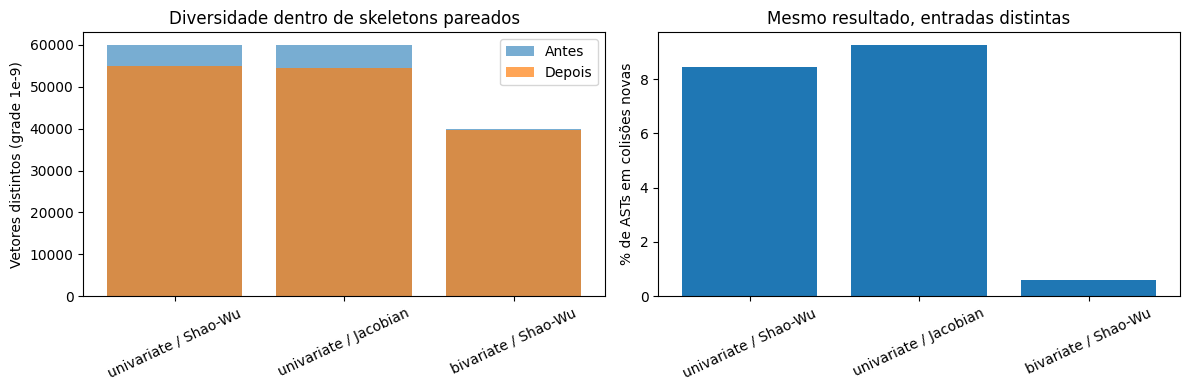

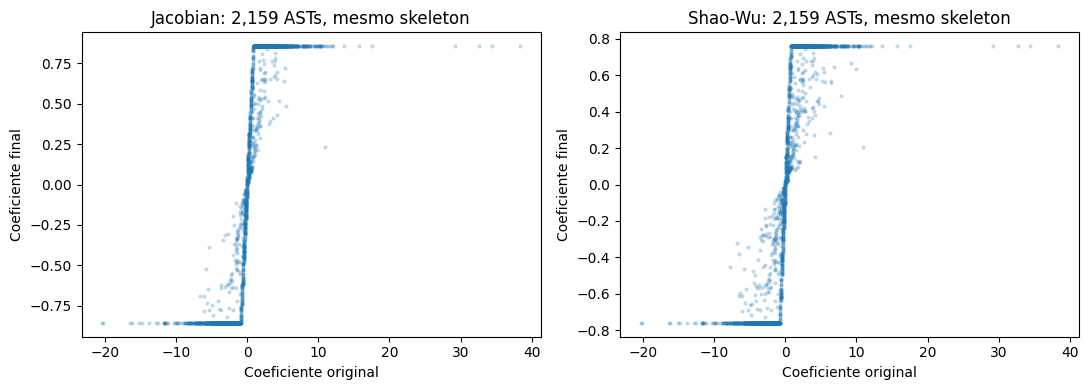

,method,n,unique_before_9,unique_after_9,std_before,std_after
0,Jacobian,2159,2159,805,3.869132,0.726871
1,Shao-Wu,2159,2159,883,3.869132,0.633225


In [5]:
# Distribuições condicionadas em skeletons idênticos: os mais frequentes por método/coorte.
display(Markdown('### Variedade por skeleton (12 grupos mais frequentes de cada coorte/método)'))
top = groups.sort_values('n',ascending=False).groupby(['cohort','method'],sort=False).head(12)
display(top[['cohort','method','skeleton','n','unique_before_9','unique_after_9','new_collision_samples_9']])
display(Markdown('### Constantes efetivas: quantis e valores distintos por monômio'))
display(slots.sort_values('n',ascending=False).head(36))

fig,axes = plt.subplots(1,2,figsize=(12,4))
plot = summary[summary.method.isin(['Jacobian','Shao-Wu'])]
labels = plot.cohort+' / '+plot.method
axes[0].bar(labels,plot.unique_before_9,label='Antes',alpha=.6)
axes[0].bar(labels,plot.unique_after_9,label='Depois',alpha=.7)
axes[0].set(ylabel='Vetores distintos (grade 1e-9)',title='Diversidade dentro de skeletons pareados')
axes[0].legend()
axes[1].bar(labels,100*plot.new_collision_sample_fraction_9)
axes[1].set(ylabel='% de ASTs em colisões novas',title='Mesmo resultado, entradas distintas')
for ax in axes: ax.tick_params(axis='x',rotation=25)
plt.tight_layout(); plt.show()

# Um skeleton linear comum: coeficiente final versus original, estritamente lag 1.
linear_support = (((0,1),),)
fig,axes = plt.subplots(1,2,figsize=(11,4))
linear_summary = []
for ax,method in zip(axes,['Jacobian','Shao-Wu']):
    g = df[(df.cohort=='univariate') & (df.method==method) &
           df.input_skeleton.map(lambda x:x==linear_support) & df.skeleton.map(lambda x:x==linear_support)]
    x=np.array([v[0] for v in g.input_coefficients]); y=np.array([v[0] for v in g.coefficients])
    ax.scatter(x,y,s=4,alpha=.2,rasterized=True)
    ax.set(title=f'{method}: {len(g):,} ASTs, mesmo skeleton',xlabel='Coeficiente original',ylabel='Coeficiente final')
    linear_summary.append(dict(method=method,n=len(g),unique_before_9=len(set(np.round(x,9))),
                               unique_after_9=len(set(np.round(y,9))),std_before=float(x.std()),std_after=float(y.std())))
plt.tight_layout(); plt.show()
display(pd.DataFrame(linear_summary))


## Interpretação e limites

A normalização perde a magnitude global quando um limite homogêneo está ativo: ao multiplicar
uma função por um fator positivo k, o limite também cresce por k, e a escala pode diminuir por k.
Isso não elimina necessariamente razões entre coeficientes. A saturação muda ainda as funções
básicas em produtos não lineares; ela é medida separadamente.

Colisões da equação-alvo em sistemas bivariados **não provam igualdade do sistema inteiro**.
Os gráficos de trajetórias são controles do exemplo inicial, não uma simulação de todas as
100 mil ASTs. Nenhum teste de trajetórias finitas prova identidade funcional. As contagens
canônicas são mais adequadas à pergunta sobre diversidade dos parâmetros.

Grupos unitários ficam nas métricas globais, mas não permitem estimar variabilidade condicional.
As distribuições de coeficientes exigem pelo menos 20 membros por grupo. A taxa de colisão
conta amostras cujo vetor final arredondado é compartilhado por pelo menos dois vetores
originais arredondados distintos dentro do mesmo par de skeletons; não confunde duplicatas
já presentes no gerador com perda nova. O número de vetores é somado por estrato, não uma
deduplicação global entre estratos. Grades mais finas podem separar artefatos de ponto flutuante
de colapsos matemáticos; a tabela mostra as três resoluções.


In [6]:
# REGISTRO COMPLETO DO EXPERIMENTO — configuração, proveniência, sementes, métricas e conclusão.
source_paths = sorted((ROOT/'src/tsfmxai/generators').glob('*.py')) + [
    ROOT/'src/tsfmxai/representations/expression.py',
    ROOT/'src/tsfmxai/representations/canonical_polynomial.py',
    ROOT/'scripts/check_generation_overview.py',
    ROOT/'report/english/chapters/implemented_generator/06_generation_overview.tex']
scientific_summary = [
    'Relatório confirmado: R1=x e R2=2x colidem nos drifts J/F; histórico e ruído devem ser compartilhados para trajetórias iguais.',
    '3x+1 e 2x+1 não colidem; 3x+1.5 e 2x+1 colidem numericamente nos dois construtores.',
    'Frequências condicionais ao prior restrito; colisões bivariadas são por equação, não por sistema completo.']
for row in summary.to_dict('records'):
    if row['method'] in ['Jacobian','Shao-Wu']:
        scientific_summary.append(f"{row['cohort']} / {row['method']}: {row['unique_before_9']} vetores antes e {row['unique_after_9']} depois; {100*row['new_collision_sample_fraction_9']:.2f}% das ASTs em colisões novas na grade 1e-9.")
record = dict(
    question='Quanto os construtores reduzem a diversidade de coeficientes dentro de skeletons iguais?',
    hypothesis='Limites ativos removem magnitude global e podem causar colisões; interceptos não proporcionais preservam diferenças.',
    configuration=dict(univariate_asts=N_UNIVARIATE,bivariate_systems=N_BIVARIATE_SYSTEMS,
        total_asts=ast_count,tree=asdict(TREE),jacobian=asdict(J_CONFIG),shao_wu=asdict(F_CONFIG),
        shao_wu_bivariate=asdict(F2_CONFIG),canonical_max_degree=MAX_DEGREE,
        canonical_max_terms=10000,canonical_max_coefficient_terms=10000,
        decimal_grids=DECIMALS,minimum_group_size_for_slot_stats=20,
        example_steps=128,example_initial_history=initial.tolist(),
        example_noise='Uniform(-sqrt(3)*0.05,sqrt(3)*0.05), shared across examples; controlled input, not default Gaussian Shao-Wu law'),
    seeds=dict(root=ROOT_SEED,derivation='derive_sample_seed(root, global_ast_index), indices 0..99999; univariate first; bivariate system then target',
               trajectory_control=PATH_SEED,report_script=20261027),
    provenance=dict(git_head=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
        git_status=subprocess.check_output(['git','status','--short'],cwd=ROOT,text=True),
        source_sha256={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in source_paths},
        python=sys.version,platform=platform.platform(),processor=platform.processor(),
        packages={name:metadata.version(name) for name in ['numpy','pandas','matplotlib','nbformat','nbclient','scipy']},
        backend='CPU NumPy; exact rational canonicalization of binary floats'),
    metrics=dict(valid_certificates=certificate_count,summary=summary.to_dict('records'),
                 linear_skeleton=linear_summary,trajectory_controls=path_checks,
                 elapsed_seconds=time.perf_counter()-started),
    scientific_summary=scientific_summary,
    reproduction='From repository root: .\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 experiments/canonicalization/08_contraction_parameter_diversity.ipynb',
    artifacts='Only this executed notebook; ASTs and detailed tables regenerated in memory; no dataset or sidecars.')
print(json.dumps(record,ensure_ascii=False,indent=2))
display(Markdown('\n\n'.join(scientific_summary)))


{
  "question": "Quanto os construtores reduzem a diversidade de coeficientes dentro de skeletons iguais?",
  "hypothesis": "Limites ativos removem magnitude global e podem causar colisões; interceptos não proporcionais preservam diferenças.",
  "configuration": {
    "univariate_asts": 60000,
    "bivariate_systems": 20000,
    "total_asts": 100000,
    "tree": {
      "minimum_operators": 1,
      "maximum_operators": 3,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 3,
      "parameter_probability": 0.55,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "minimum_parameter_magnitude": 0.05,
      "maximum_parameter_magnitude": 3.0,
      "require_lag": true,
      "coefficient_gate_lags": true
    },
    "jacobian": {
      "tree_config": {
        "minimum_operators": 1,
        "maximum_operators": 3,
        "num_series": 1,
        "minimum_lag": 1,
        "maximum_lag": 3,
        "parameter_probability": 0.55,
        "lag_probability": 0

Relatório confirmado: R1=x e R2=2x colidem nos drifts J/F; histórico e ruído devem ser compartilhados para trajetórias iguais.

3x+1 e 2x+1 não colidem; 3x+1.5 e 2x+1 colidem numericamente nos dois construtores.

Frequências condicionais ao prior restrito; colisões bivariadas são por equação, não por sistema completo.

univariate / Shao-Wu: 60000 vetores antes e 54969 depois; 8.45% das ASTs em colisões novas na grade 1e-9.

univariate / Jacobian: 60000 vetores antes e 54480 depois; 9.26% das ASTs em colisões novas na grade 1e-9.

bivariate / Shao-Wu: 40000 vetores antes e 39796 depois; 0.59% das ASTs em colisões novas na grade 1e-9.

## Avalia??o adicional: sele??o de ASTs originais por trajet?rias finitas

Sem tratamento ou reten??o de lags, amostramos 1.000 ASTs univariadas e 500 sistemas bivariados (2.000 ASTs), usando o mesmo prior restrito acima. Cada sistema recebe uma trajet?ria gaussiana de 256 passos e at? tr?s novos hist?ricos aleat?rios se falhar. N?o reamostramos sistemas: preservamos todos para comparar aceitos e rejeitados. O ru?do ? fixo entre tentativas. Aceita??o exige valores finitos e represent?veis em float32; finitude em 128 passos ? registrada separadamente. Isso n?o certifica estabilidade ou estacionariedade.

Skeleton significa suporte can?nico com fontes, lags e multiplicidade. Repeti??o de skeleton n?o implica repeti??o de coeficientes nem igualdade funcional. A aceita??o bivariada pertence ao sistema inteiro; a compara??o univariada permite atribui??o direta ? equa??o. Coeficientes can?nicos efetivos s?o mais informativos que par?metros internos multiplicados entre si. A inicializa??o usa as fam?lias aleat?rias do treinamento; o prior de ?rvores ? o deste notebook, n?o o combinat?rio do treinamento.

,systems,accepted,finite128,history_attempts,acceptance_fraction
cohort,,,,,
bivariate,500,211,339,1374,0.422
univariate,1000,549,775,2380,0.549


,cohort,subset,asts,skeletons,exact_mechanisms
0,bivariate,all,1000,151,1000
1,bivariate,accepted,422,70,422
2,bivariate,rejected,578,134,578
3,univariate,all,1000,65,1000
4,univariate,accepted,549,43,549
5,univariate,rejected,451,44,451


lag_leaves  distinct_lags  degree  lag_coefficient_l1  \
cohort     accepted                                                          
bivariate  False            1.0            1.0     1.0            2.576960   
           True             1.0            1.0     1.0            1.329230   
univariate False            2.0            1.0     1.0            2.982861   
           True             1.0            1.0     1.0            1.161197   

                     lag_coefficient_max  raw_parameter_mean  
cohort     accepted                                           
bivariate  False                2.265766            1.594668  
           True                 1.221585            1.360565  
univariate False                2.636867            1.735193  
           True                 1.084544            1.340081

size      mean
cohort     degree                
bivariate  1        889  0.440945
           2        109  0.266055
           3          2  0.500000
univariate 1        900  0.552222
           2         91  0.483516
           3          9  0.888889

,skeleton,n,accepted,accepted_l1_median,rejected_l1_median,difference
4,"((), ((0, 3),))",198,178,1.400449,3.185230,-1.784782
2,"((), ((0, 1),))",191,83,0.708302,2.269014,-1.560712
0,"((), ((0, 2),))",179,115,1.121906,2.564657,-1.442750
6,"((), ((0, 1),), ((0, 2),))",53,19,1.787287,3.383927,-1.596640
1,"((), ((0, 2),), ((0, 3),))",52,14,1.828833,4.191926,-2.363093
12,"((), ((0, 1),), ((0, 3),))",41,17,2.104248,3.845812,-1.741564
5,"(((0, 2),),)",37,17,0.450748,3.709876,-3.259128
10,"(((0, 3),),)",32,18,1.352493,4.016000,-2.663507
8,"(((0, 1),),)",30,12,0.445469,4.062120,-3.616651
11,"(((0, 1),), ((0, 2),))",28,8,2.232366,3.427492,-1.195126


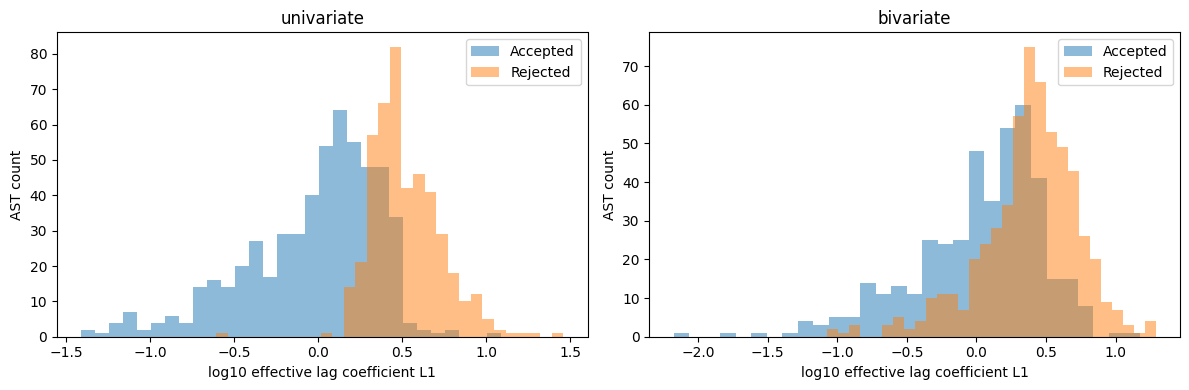

,cohort,accepted_skeletons,same_size_random_mean,random_q025,random_q975
0,bivariate,70,95.090,85.0,106.0
1,univariate,43,48.885,42.0,55.0


{
  "acceptance": [
    {
      "cohort": "bivariate",
      "systems": 500,
      "accepted": 211,
      "finite128": 339,
      "history_attempts": 1374,
      "acceptance_fraction": 0.422
    },
    {
      "cohort": "univariate",
      "systems": 1000,
      "accepted": 549,
      "finite128": 775,
      "history_attempts": 2380,
      "acceptance_fraction": 0.549
    }
  ],
  "diversity": [
    {
      "cohort": "bivariate",
      "subset": "all",
      "asts": 1000,
      "skeletons": 151,
      "exact_mechanisms": 1000
    },
    {
      "cohort": "bivariate",
      "subset": "accepted",
      "asts": 422,
      "skeletons": 70,
      "exact_mechanisms": 422
    },
    {
      "cohort": "bivariate",
      "subset": "rejected",
      "asts": 578,
      "skeletons": 134,
      "exact_mechanisms": 578
    },
    {
      "cohort": "univariate",
      "subset": "all",
      "asts": 1000,
      "skeletons": 65,
      "exact_mechanisms": 1000
    },
    {
      "cohort": "univariate",


In [2]:
# Experimento adicional independente: reutiliza apenas imports/configura??o da c?lula inicial.
from tsfmxai.generators.initialization import RandomHistorySpec, sample_random_history
from tsfmxai.generators.multiseries import stream_seed
from tsfmxai.generators.trajectory import required_multivariate_history_length
from tsfmxai.representations.expression import walk
ORIGINAL_SEED = 20261118
original_started = time.perf_counter()
original_rows = []
original_system_rows = []
original_paths = []
original_initialization = RandomHistorySpec()
for cohort, count, channels in [('univariate', 1000, 1), ('bivariate', 500, 2)]:
    for sid in range(count):
        mechanisms = [sample_random_mechanism(replace(TREE, num_series=channels),
            seed=stream_seed(ORIGINAL_SEED, channels, sid, target), sample_index=sid*channels+target)
            for target in range(channels)]
        expressions = tuple(m.expression for m in mechanisms)
        bindings = tuple(m.binding for m in mechanisms)
        length = required_multivariate_history_length(expressions, bindings)
        innovations = np.random.default_rng(stream_seed(ORIGINAL_SEED, channels, sid, 90)).normal(0., .05, (channels, 256))
        accepted = False
        finite128 = False
        for attempt in range(4):
            history, _ = sample_random_history(original_initialization, channels, length,
                np.random.default_rng(stream_seed(ORIGINAL_SEED, channels, sid, 91, attempt)))
            try:
                path = simulate_innovation_path(expressions, bindings, history, innovations)
                with np.errstate(over='ignore', invalid='ignore'):
                    converted = path.astype('float32')
                valid = np.isfinite(path).all(axis=0) & np.isfinite(converted).all(axis=0)
                finite128 |= bool(path.shape[1] >= 128 and valid[:128].all())
                accepted = bool(path.shape[1] == 256 and valid.all())
            except OverflowError:
                accepted = False
            if accepted:
                if len(original_paths) < 8: original_paths.append((cohort, sid, path.copy()))
                break
        original_system_rows.append(dict(cohort=cohort, system=sid, accepted=accepted,
            finite128=finite128, attempts=attempt+1))
        for target, m in enumerate(mechanisms):
            poly = canonicalize_polynomial(m.expression, m.binding, max_degree=MAX_DEGREE)
            lag_terms = [t for t in poly.terms if t.monomial]
            coeff = np.array([abs(float(t.coefficient)) for t in lag_terms])
            atoms = {a for term in poly.skeleton for a in term}
            original_rows.append(dict(cohort=cohort,system=sid,target=target,accepted=accepted,
                skeleton=poly.skeleton, exact=tuple(t.coefficient_exact for t in poly.terms),
                lag_leaves=sum(isinstance(x,Lag) for x in walk(m.expression)),
                distinct_lags=len(atoms), degree=max((len(t.monomial) for t in poly.terms),default=0),
                lag_coefficient_l1=float(coeff.sum()), lag_coefficient_max=float(coeff.max()) if coeff.size else 0.,
                raw_parameter_mean=float(np.mean(np.abs(list(m.binding.parameter_values.values()))))))
original_df = pd.DataFrame(original_rows)
original_systems = pd.DataFrame(original_system_rows)
assert len(original_df) == 2000 and len(original_systems) == 1500
original_acceptance = original_systems.groupby('cohort').agg(systems=('accepted','size'), accepted=('accepted','sum'),
    finite128=('finite128','sum'), history_attempts=('attempts','sum'))
original_acceptance['acceptance_fraction'] = original_acceptance.accepted/original_acceptance.systems
display(original_acceptance)
original_diversity = []
for cohort, group in original_df.groupby('cohort'):
    for label, g in [('all',group),('accepted',group[group.accepted]),('rejected',group[~group.accepted])]:
        original_diversity.append(dict(cohort=cohort, subset=label, asts=len(g), skeletons=len(set(g.skeleton)),
            exact_mechanisms=len(set(zip(g.skeleton,g.exact)))))
display(pd.DataFrame(original_diversity))
features = ['lag_leaves','distinct_lags','degree','lag_coefficient_l1','lag_coefficient_max','raw_parameter_mean']
display(original_df.groupby(['cohort','accepted'])[features].median())
display(original_df.groupby(['cohort','degree']).accepted.agg(['size','mean']))
# Within-skeleton comparison controls for support; only univariate mixed-outcome groups.
within = []
for skeleton,g in original_df[original_df.cohort=='univariate'].groupby('skeleton',sort=False):
    if g.accepted.any() and (~g.accepted).any():
        a=g[g.accepted].lag_coefficient_l1.median(); r=g[~g.accepted].lag_coefficient_l1.median()
        within.append(dict(skeleton=str(skeleton), n=len(g), accepted=int(g.accepted.sum()),
            accepted_l1_median=float(a),rejected_l1_median=float(r), difference=float(a-r)))
within_df = pd.DataFrame(within)
display(within_df.sort_values('n',ascending=False).head(20) if len(within_df) else within_df)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,cohort in zip(axes,['univariate','bivariate']):
    g=original_df[original_df.cohort==cohort]
    for accepted,label in [(True,'Accepted'),(False,'Rejected')]:
        values=g.loc[g.accepted==accepted,'lag_coefficient_l1']
        ax.hist(np.log10(np.maximum(values,1e-12)),bins=30,alpha=.5,label=label)
    ax.set(title=cohort,xlabel='log10 effective lag coefficient L1',ylabel='AST count'); ax.legend()
plt.tight_layout(); plt.show()
original_metrics = dict(acceptance=original_acceptance.reset_index().to_dict('records'),diversity=original_diversity,
    feature_medians=original_df.groupby(['cohort','accepted'])[features].median().reset_index().to_dict('records'),
    mixed_outcome_univariate_skeletons=len(within_df),
    mixed_skeletons_lower_accepted_l1=int((within_df.difference<0).sum()) if len(within_df) else 0,
    elapsed_seconds=time.perf_counter()-original_started)
# Equal-size random subsets distinguish sample-size loss from selection loss.
rarefaction = []
for cohort,g in original_df.groupby('cohort'):
    accepted_g = g[g.accepted]
    rng = np.random.default_rng(stream_seed(ORIGINAL_SEED, 99, len(g)))
    values = [len(set(g.iloc[rng.choice(len(g),len(accepted_g),replace=False)].skeleton)) for _ in range(200)]
    rarefaction.append(dict(cohort=cohort, accepted_skeletons=len(set(accepted_g.skeleton)),
        same_size_random_mean=float(np.mean(values)), random_q025=float(np.quantile(values,.025)),
        random_q975=float(np.quantile(values,.975))))
original_metrics['equal_size_diversity'] = rarefaction
display(pd.DataFrame(rarefaction))
print(json.dumps(original_metrics,ensure_ascii=False,indent=2))


In [3]:
# REGISTRO COMPLETO DO EXPERIMENTO ADICIONAL ? todo o registro permanece nesta c?lula.
original_summary = [
    'Aceita??o significa trajet?ria finita e represent?vel em float32 por 256 passos, n?o estabilidade matem?tica.',
    'Skeletons distintos s?o comparados canonicamente; mecanismos iguais exigem tamb?m coeficientes iguais.',
    'Compara??es bivariadas s?o condicionadas ? aceita??o conjunta; par?metros menores n?o s?o condi??o necess?ria ou suficiente.',
    'O prior RandomTreeConfig com gates e magnitudes at? 3 difere do prior combinat?rio atual do treinamento.']
for row in original_metrics['acceptance']:
    original_summary.append(f"{row['cohort']}: {row['accepted']}/{row['systems']} sistemas aceitos ({row['acceptance_fraction']:.1%}).")
original_summary.append(f"Nos {len(within_df)} skeletons univariados com ambos os resultados, {(within_df.difference<0).sum()} tiveram mediana L1 menor entre aceitos.")
for row in original_metrics['equal_size_diversity']:
    original_summary.append(f"{row['cohort']}: {row['accepted_skeletons']} skeletons aceitos, contra m?dia {row['same_size_random_mean']:.1f} em subconjuntos aleat?rios do mesmo tamanho.")
original_summary.append('A hip?tese ? apoiada para magnitude efetiva; quantidade de lags sozinha discrimina menos. Resultados dependem do horizonte, prior e inicializa??o; valores finitos podem crescer fortemente.')
original_record = dict(question='A sele??o por trajet?rias finitas reduz diversidade de skeletons e favorece depend?ncia menor de lags?',
    hypothesis='Aceitos apresentam menor depend?ncia efetiva de lags; avaliar tamb?m dentro do mesmo suporte.',
    configuration=dict(tree=asdict(TREE),univariate_systems=1000,bivariate_systems=500,steps=256,short_horizon=128,
        histories_per_system_max=4,initialization=asdict(original_initialization),noise_family='Gaussian',noise_std=.05,
        simulation_dtype='float64',acceptance_dtype='float32',stop_threshold=None,system_resampling=False,
        treatment='original only; no lag thinning',canonical_max_degree=MAX_DEGREE),
    seeds=dict(root=ORIGINAL_SEED,mechanism='stream_seed(root,channels,system,target)',
        noise='stream_seed(root,channels,system,90)',history='stream_seed(root,channels,system,91,attempt)'),
    provenance=dict(git_head=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
        git_status=subprocess.check_output(['git','status','--short'],cwd=ROOT,text=True),python=sys.version,
        platform=platform.platform(),numpy=np.__version__,
        source_sha256={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted((ROOT/'src/tsfmxai/generators').glob('*.py'))+list((ROOT/'src/tsfmxai/representations').glob('*.py'))}),
    metrics=original_metrics,scientific_summary=original_summary,
    reproduction='From repository root: .\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 experiments/canonicalization/08_contraction_parameter_diversity.ipynb',
    artifacts='Only this executed notebook. Existing experiment outputs preserved; additional cells executed independently with initial configuration cell.')
print(json.dumps(original_record,ensure_ascii=False,indent=2))
display(Markdown('\n\n'.join(original_summary)))


{
  "question": "A sele??o por trajet?rias finitas reduz diversidade de skeletons e favorece depend?ncia menor de lags?",
  "hypothesis": "Aceitos apresentam menor depend?ncia efetiva de lags; avaliar tamb?m dentro do mesmo suporte.",
  "configuration": {
    "tree": {
      "minimum_operators": 1,
      "maximum_operators": 3,
      "num_series": 1,
      "minimum_lag": 1,
      "maximum_lag": 3,
      "parameter_probability": 0.55,
      "lag_probability": 0.45,
      "add_probability": 0.8,
      "minimum_parameter_magnitude": 0.05,
      "maximum_parameter_magnitude": 3.0,
      "require_lag": true,
      "coefficient_gate_lags": true
    },
    "univariate_systems": 1000,
    "bivariate_systems": 500,
    "steps": 256,
    "short_horizon": 128,
    "histories_per_system_max": 4,
    "initialization": {
      "name": "random families",
      "constant_probability": 0.5,
      "constant_magnitude": [
        0.0,
        1.0
      ],
      "noise_probability": 0.5,
      "noise_radi

Aceita??o significa trajet?ria finita e represent?vel em float32 por 256 passos, n?o estabilidade matem?tica.

Skeletons distintos s?o comparados canonicamente; mecanismos iguais exigem tamb?m coeficientes iguais.

Compara??es bivariadas s?o condicionadas ? aceita??o conjunta; par?metros menores n?o s?o condi??o necess?ria ou suficiente.

O prior RandomTreeConfig com gates e magnitudes at? 3 difere do prior combinat?rio atual do treinamento.

bivariate: 211/500 sistemas aceitos (42.2%).

univariate: 549/1000 sistemas aceitos (54.9%).

Nos 22 skeletons univariados com ambos os resultados, 22 tiveram mediana L1 menor entre aceitos.

bivariate: 70 skeletons aceitos, contra m?dia 95.1 em subconjuntos aleat?rios do mesmo tamanho.

univariate: 43 skeletons aceitos, contra m?dia 48.9 em subconjuntos aleat?rios do mesmo tamanho.

A hip?tese ? apoiada para magnitude efetiva; quantidade de lags sozinha discrimina menos. Resultados dependem do horizonte, prior e inicializa??o; valores finitos podem crescer fortemente.